# Inférence avec le meilleur modèle obtenu: early fusion

Ce notebook prédit la classe d'un plat à partir d'une **image** et de son **titre**, avec le modèle
**early fusion** 

Deux façons de lui donner des données :

- **A. Test dataset sur Modal** déjà sur Modal : tu donnes leurs noms de fichier, ou tu en tires au hasard. On connaît leur vraie classe, donc on voit si le modèle a raison.
- **B. Images locale** depuis ton ordinateur, avec un titre que tu écris.

## 1. Préparation

Cette cellule connecte le notebook au projet et définit `show`, qui affiche les résultats :
une image par colonne, avec en dessous son titre, sa vraie classe (si on la connaît) et les
prédictions des trois modèles. **Vert** = juste, **rouge** = faux, gris = vraie classe inconnue.
Le nombre entre parenthèses est la probabilité donnée par le modèle.

In [14]:
import io
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import modal
from PIL import Image

ROOT = Path("..").resolve()                   # project root, seen from notebooks/
sys.path.insert(0, str(ROOT))
from modal_app import app, predict_samples, predict_test_samples

MODEL = "early"                               # fusion run to use (folder /ckpt/early)
TOP_K = 3                                     # how many classes to list for the fusion


def show(images: list[bytes], result: dict, true_classes: list[str | None]) -> None:
    # One column per sample: image, then title, true class and each model's top-1 prediction.
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 7), squeeze=False)
    for ax, image, pred, true in zip(axes[0], images, result["predictions"], true_classes):
        ax.imshow(Image.open(io.BytesIO(image)).convert("RGB"))
        ax.axis("off")
        lines = [textwrap.shorten(pred["title"] or "(pas de titre)", 45),
                 f"vraie classe : {true or '?'}"]
        colors = ["black", "black"]
        for model_name, label in (("image", "image seule"), ("text", "texte seul"), ("fusion", "FUSION")):
            name, prob = pred[model_name][0]
            lines.append(f"{label} : {name} ({prob:.2f})")
            colors.append("gray" if true is None else ("green" if name == true else "red"))
        for i, (line, color) in enumerate(zip(lines, colors)):
            ax.text(0.5, -0.05 - 0.085 * i, line, transform=ax.transAxes, ha="center", va="top",
                    fontsize=10, color=color, fontweight="bold" if line.startswith("FUSION") else None)
    fig.subplots_adjust(bottom=0.4, top=0.92, wspace=0.3)
    plt.show()
    for pred in result["predictions"]:                 # full top-k of the fusion, as text
        print(f"{pred['title'][:60]!r:<64} fusion top-{TOP_K}: "
              + ", ".join(f"{name} ({prob:.2f})" for name, prob in pred["fusion"]))

## A. Inférence du test dataset

- Pour choisir des images précises, mets leurs noms dans `SAMPLE_IDS`, par exemple
  `["pizza_12.jpg", "sushi_85.jpg"]` (les noms sont de la forme `<classe>_<numéro>.jpg`, voir
  `results/early_test_predictions.csv`).
- Si `SAMPLE_IDS` est vide, `N_RANDOM` images sont tirées au hasard dans le test. Change `SEED` pour
  avoir un autre tirage (même `SEED` = mêmes images).

✓ Initialized. View run at 
https://modal.com/apps/zaynabezzahraouy/main/ap-PZSIli3aeNpYObnrnk5tWb
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋
├── ⠋
⠏ Creating objects...
├── ⠸ Creating mount 
│   /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py: Finalizing index of 1 files
├── ⠸ Creating mount 
│   /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs: Finalizing index of 7 files
⠹ Creating objects...
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs
├── ✓ Uploaded PythonPackage:src
├── ⠋ Creating Function check_env...
├── ⠋ Creating Function download_data...
├── ⠋ Creating Function inspect_data...
├── ⠋ Creating Function split_data...
├── ⠋ Creating Function summarize_splits...
├── ⠋ Creating Function test_data...
├── ⠋ Creating Function test_im

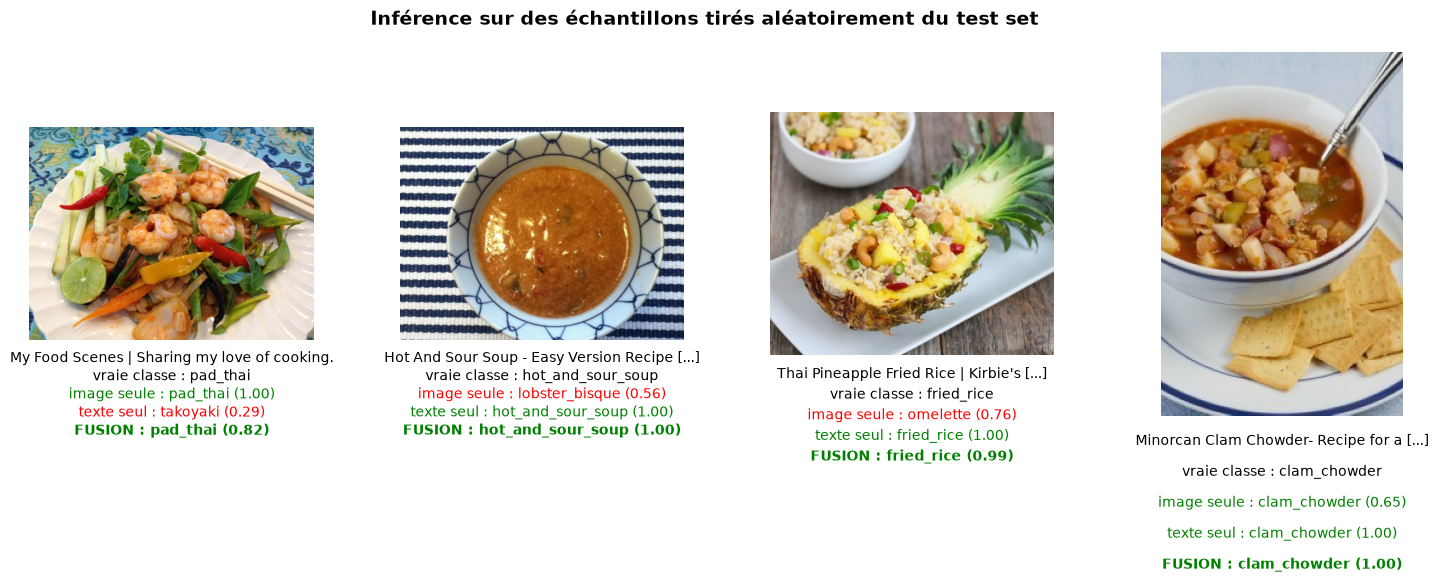

'My Food Scenes | Sharing my love of cooking.'                   fusion top-3: pad_thai (0.82), ramen (0.12), fried_rice (0.01)
'Hot And Sour Soup - Easy Version Recipe - Chinese.Food.com'     fusion top-3: hot_and_sour_soup (1.00), french_onion_soup (0.00), chicken_curry (0.00)
"Thai Pineapple Fried Rice | Kirbie's Cravings | A San Diego "   fusion top-3: fried_rice (0.99), breakfast_burrito (0.01), omelette (0.00)
'Minorcan Clam Chowder- Recipe for a spicy soup that will rea'   fusion top-3: clam_chowder (1.00), french_fries (0.00), hot_and_sour_soup (0.00)


In [12]:
SAMPLE_IDS = []          # e.g. ["crab_cakes_391.jpg", "sushi_85.jpg"]; empty = random draw
N_RANDOM = 4
SEED = 42

with modal.enable_output(), app.run():
    result = predict_test_samples.remote(SAMPLE_IDS, N_RANDOM, SEED, TOP_K, MODEL)

samples = result["samples"]
show([s["image"] for s in samples], result, [s["true"] for s in samples])

## 3. Option B : tes propres images

- Ajoute un couple `(chemin de l'image, titre)` par image dans `MY_SAMPLES`. Le titre joue le rôle du
  titre de la page web : un nom de recette, un titre de blog... Le modèle texte a appris sur des
  titres en anglais.
- La vraie classe à mettre dans `MY_TRUE_CLASSES` elle est connue (même ordre, `None` sinon) : ça colore
  les prédictions en vert / rouge. Les 101 noms de classes sont ceux des dossiers, par exemple
  `pizza`, `sushi`, `apple_pie`.
- Formats acceptés : JPEG, PNG... (tout ce que PIL sait ouvrir).

✓ Initialized. View run at 
https://modal.com/apps/zaynabezzahraouy/main/ap-qIMoYNPWEYjEjsbs06f6wB
⠋ Initializing...
⠦ Creating objects...objects...
├── ⠋ Creating mount 
│   /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py: Finalizing index of 1 files
├── ⠋ Creating mount 
│   /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs: Finalizing index of 7 files
⠏ Creating objects...
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/modal_app.py
├── ✓ Uploaded /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 
│   1/codev1/configs
├── ✓ Uploaded PythonPackage:src
├── ⠋ Creating Function check_env...
├── ⠋ Creating Function download_data...
├── ⠋ Creating Function inspect_data...
├── ⠋ Creating Function split_data...
├── ⠋ Creating Function summarize_splits...
├── ⠋ Creating Function test_data...
├── ⠋ Creating Function test_image_model...
├── ⠋ Creating Functi

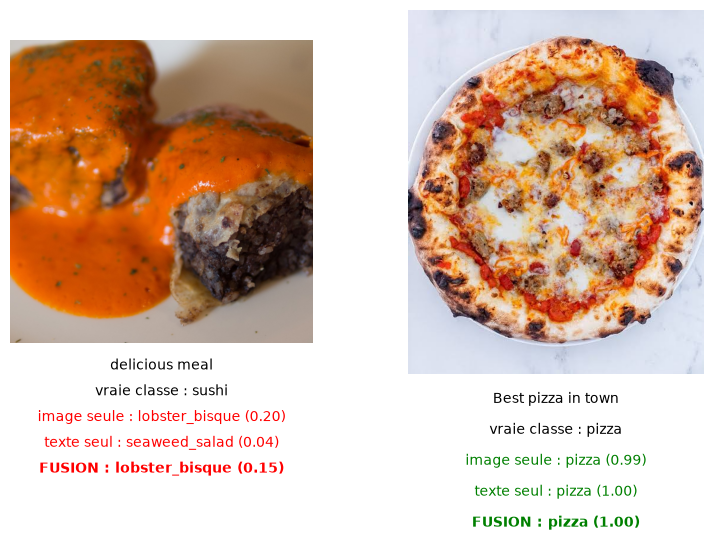

'delicious meal'                                                 fusion top-3: lobster_bisque (0.15), escargots (0.06), fried_calamari (0.06)
'Best pizza in town'                                             fusion top-3: pizza (1.00), lasagna (0.00), garlic_bread (0.00)


In [15]:
MY_SAMPLES = [("/Users/zaynabez-zahraouy/Downloads/test1.jpg","delicious meal"),("/Users/zaynabez-zahraouy/Downloads/test2.jpeg","Best pizza in town")]          # (image path, title), e.g. ("/Users/me/Pictures/pizza.jpg", "Homemade margherita pizza")]
MY_TRUE_CLASSES = ["sushi", "pizza"]     # same order, e.g. ["pizza"]; leave empty if unknown

images = [Path(path).expanduser().read_bytes() for path, _ in MY_SAMPLES]
titles = [title for _, title in MY_SAMPLES]
true_classes = MY_TRUE_CLASSES or [None] * len(MY_SAMPLES)

with modal.enable_output(), app.run():
    result = predict_samples.remote(images, titles, TOP_K, MODEL)

show(images, result, true_classes)